In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (775, 14)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [ ]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names and data types
df.info()

Number of rows: 775
Number of columns: 14
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 775 entries, 0 to 774
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     775 non-null    int64  
 1   pclass       775 non-null    int64  
 2   sex          775 non-null    object 
 3   age          775 non-null    float64
 4   sibsp        775 non-null    int64  
 5   parch        775 non-null    int64  
 6   fare         775 non-null    float64
 7   embarked     775 non-null    object 
 8   class        775 non-null    object 
 9   who          775 non-null    object 
 10  adult_male   775 non-null    bool   
 11  embark_town  773 non-null    object 
 12  alive        775 non-null    object 
 13  alone        775 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(6)
memory usage: 74.3+ KB


In [ ]:
# Summary statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,775.0,NaN,NaN,NaN,0.412903,0.492674,0.0,0.0,0.0,1.0,1.0
pclass,775.0,NaN,NaN,NaN,2.246452,0.853574,1.0,1.0,3.0,3.0,3.0
sex,775,2,male,483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,775.0,NaN,NaN,NaN,29.581187,13.766359,0.42,21.0,28.0,36.0,80.0
sibsp,775.0,NaN,NaN,NaN,0.529032,0.990326,0.0,0.0,0.0,1.0,8.0
parch,775.0,NaN,NaN,NaN,0.420645,0.840565,0.0,0.0,0.0,1.0,6.0
fare,775.0,NaN,NaN,NaN,34.878403,52.408474,0.0,8.05,15.9,34.1979,512.3292
embarked,775,3,S,562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,775,3,Third,401,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,775,3,man,443,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Count missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Count duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

Number of duplicate rows: 0


Did Not Survive    455
Survived           320
Name: count, dtype: int64


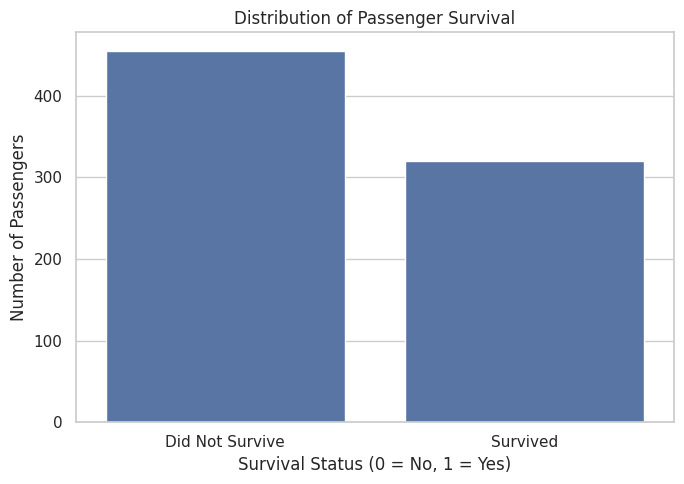

In [ ]:
survival_counts = df["survived"].value_counts().sort_index()

survival_counts.index = ["Did Not Survive", "Survived"]

print(survival_counts)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="survived")

plt.title("Distribution of Passenger Survival")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])
plt.tight_layout()
plt.show()

Survival rate by gender (%):
sex
female    73.97
male      21.53
Name: survived, dtype: float64


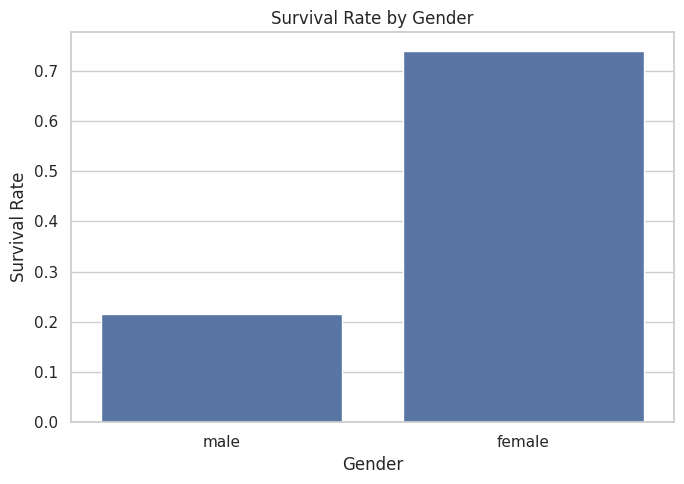

In [ ]:
gender_survival = df.groupby("sex")["survived"].mean() * 100

print("Survival rate by gender (%):")
print(gender_survival.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x="sex", y="survived", errorbar=None)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

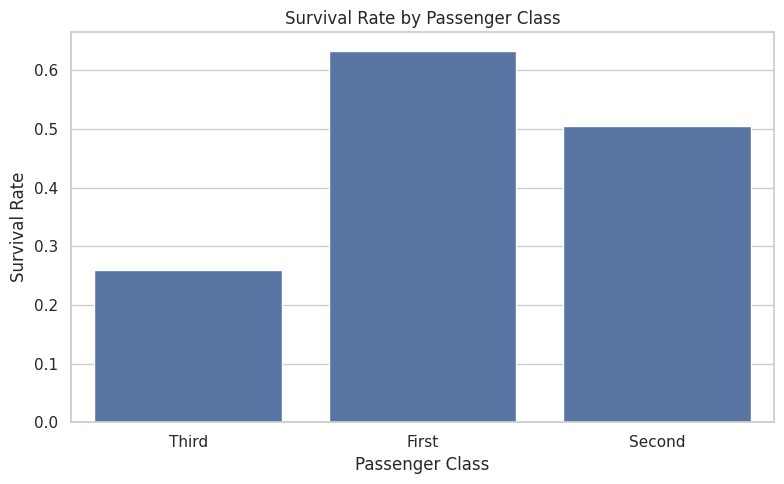

Survival rates by class (%):
class
First     63.33
Second    50.61
Third     25.94
Name: survived, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="class",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

print("Survival rates by class (%):")
print((df.groupby("class", observed=True)["survived"].mean() * 100).round(2))

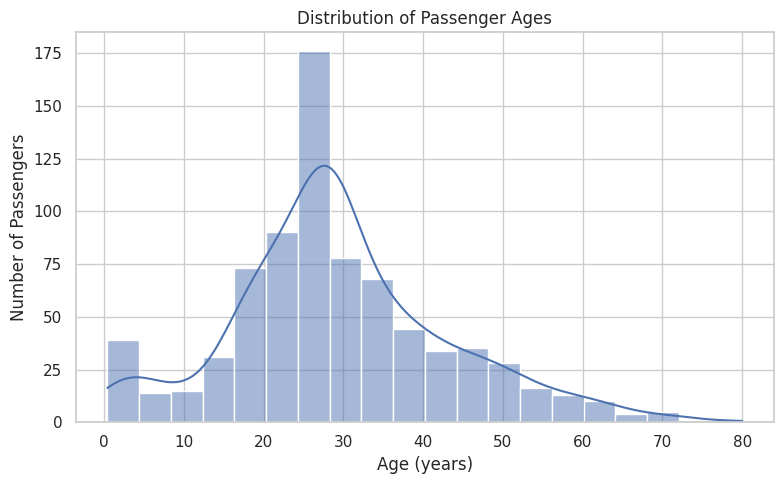

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

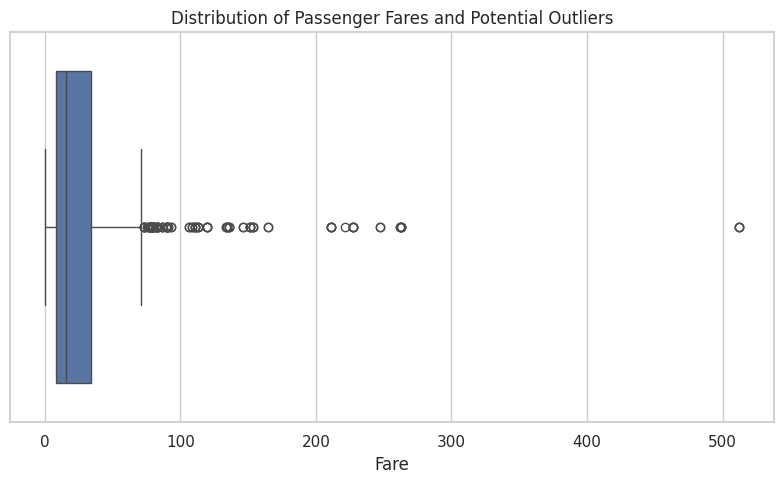

Fare summary:
count    775.000000
mean      34.878403
std       52.408474
min        0.000000
25%        8.050000
50%       15.900000
75%       34.197900
max      512.329200
Name: fare, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fare")

plt.title("Distribution of Passenger Fares and Potential Outliers")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

print("Fare summary:")
print(df["fare"].describe())

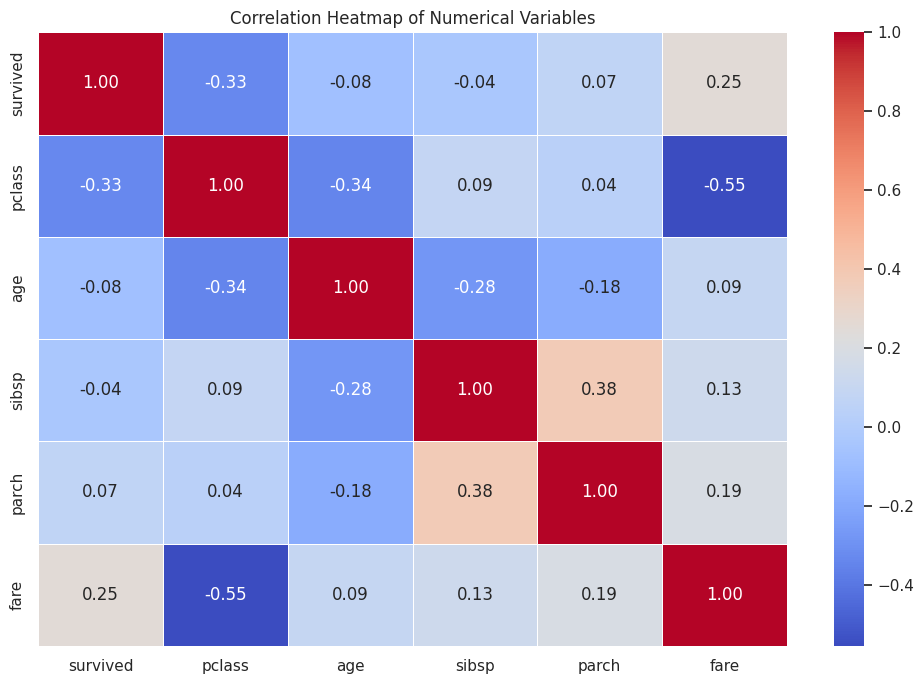

In [ ]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

Survival rate by class and gender (%):


sex,female,male
class,,
First,96.77,36.75
Second,91.67,18.48
Third,47.24,16.06


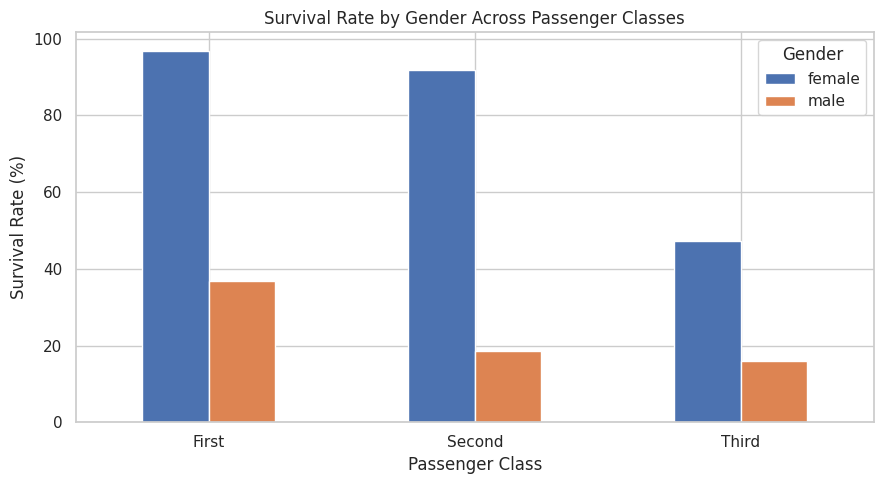

In [ ]:
survival_table = pd.pivot_table(
    df,
    values="survived",
    index="class",
    columns="sex",
    aggfunc="mean",
    observed=True
) * 100

print("Survival rate by class and gender (%):")
display(survival_table.round(2))

survival_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Survival Rate by Gender Across Passenger Classes")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.legend(title="Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()